<a href="https://colab.research.google.com/github/mehakgupta0406/credit-card-customer-churn/blob/main/01_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv("BankChurners.csv")

In [4]:
df.shape

(10127, 23)

In [6]:
df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

In [8]:
df.isna().sum()

,0
CLIENTNUM,0
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,0
Marital_Status,0
Income_Category,0
Card_Category,0
Months_on_book,0


In [9]:
df["CLIENTNUM"].duplicated().sum()

np.int64(0)

In [10]:
df["Attrition_Flag"].value_counts()

,count
Attrition_Flag,
Existing Customer,8500
Attrited Customer,1627


In [11]:
df["Attrition_Flag"].value_counts(normalize=True).mul(100).round(2)

,proportion
Attrition_Flag,
Existing Customer,83.93
Attrited Customer,16.07


The dataset contains 10,127 customers. Of these, 16.07% churned and 83.93% remained. The classes are imbalanced, with substantially fewer churned customers.

In [12]:
cols_to_drop = [
    col for col in df.columns
    if col.startswith("Naive_Bayes_Classifier")
]

df = df.drop(columns=cols_to_drop)

df.shape

(10127, 21)

In [13]:
df["Churn"] = df["Attrition_Flag"].map({
    "Existing Customer": 0,
    "Attrited Customer": 1
})

df[["Attrition_Flag", "Churn"]].head()

,Attrition_Flag,Churn
0,Existing Customer,0
1,Existing Customer,0
2,Existing Customer,0
3,Existing Customer,0
4,Existing Customer,0


In [14]:
columns_to_check = [
    "Education_Level",
    "Marital_Status",
    "Income_Category"
]

df[columns_to_check].eq("Unknown").sum()

,0
Education_Level,1519
Marital_Status,749
Income_Category,1112


In [15]:
df.groupby("Attrition_Flag")[
    ["Total_Trans_Ct", "Total_Trans_Amt", "Months_Inactive_12_mon"]
].mean().round(2)

,Total_Trans_Ct,Total_Trans_Amt,Months_Inactive_12_mon
Attrition_Flag,,,
Attrited Customer,44.93,3095.03,2.69
Existing Customer,68.67,4654.66,2.27


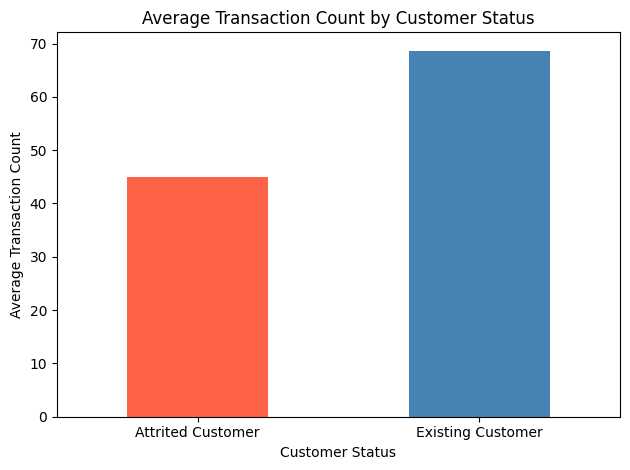

In [16]:
import matplotlib.pyplot as plt

df.groupby("Attrition_Flag")["Total_Trans_Ct"].mean().plot(
    kind="bar",
    color=["tomato", "steelblue"]
)

plt.title("Average Transaction Count by Customer Status")
plt.xlabel("Customer Status")
plt.ylabel("Average Transaction Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

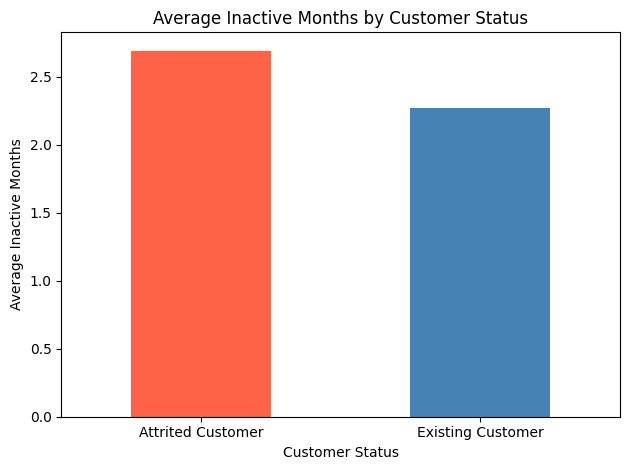

In [17]:
df.groupby("Attrition_Flag")["Months_Inactive_12_mon"].mean().plot(
    kind="bar",
    color=["tomato", "steelblue"]
)

plt.title("Average Inactive Months by Customer Status")
plt.xlabel("Customer Status")
plt.ylabel("Average Inactive Months")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

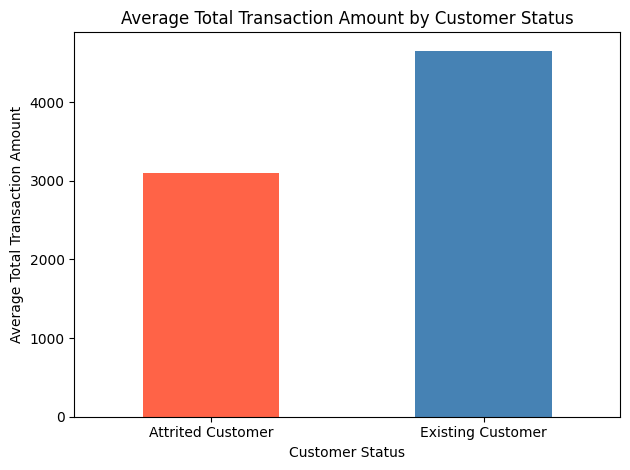

In [18]:
df.groupby("Attrition_Flag")["Total_Trans_Amt"].mean().plot(
    kind="bar",
    color=["tomato", "steelblue"]
)

plt.title("Average Total Transaction Amount by Customer Status")
plt.xlabel("Customer Status")
plt.ylabel("Average Total Transaction Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
import sqlite3

conn = sqlite3.connect("customer_churn.db")

df.to_sql(
    "customers",
    conn,
    if_exists="replace",
    index=False
)

10127

In [20]:
query = """
SELECT
    Card_Category,
    COUNT(*) AS total_customers,
    SUM(Churn) AS churned_customers,
    ROUND(100.0 * AVG(Churn), 2) AS churn_rate_pct
FROM customers
GROUP BY Card_Category
ORDER BY churn_rate_pct DESC;
"""

pd.read_sql_query(query, conn)

,Card_Category,total_customers,churned_customers,churn_rate_pct
0,Platinum,20,5,25.00
1,Gold,116,21,18.10
2,Blue,9436,1519,16.10
3,Silver,555,82,14.77


Churn rates vary across card categories. Platinum has the highest observed rate at 25%, but its small sample of 20 customers limits interpretation. Blue cardholders account for 1,519 of the 1,627 churned customers, making this segment important for understanding the overall volume of churn.

In [21]:
query = """
SELECT
    Months_Inactive_12_mon AS inactive_months,
    COUNT(*) AS total_customers,
    SUM(Churn) AS churned_customers,
    ROUND(100.0 * AVG(Churn), 2) AS churn_rate_pct
FROM customers
GROUP BY Months_Inactive_12_mon
ORDER BY inactive_months;
"""

pd.read_sql_query(query, conn)

,inactive_months,total_customers,churned_customers,churn_rate_pct
0,0,29,15,51.72
1,1,2233,100,4.48
2,2,3282,505,15.39
3,3,3846,826,21.48
4,4,435,130,29.89
5,5,178,32,17.98
6,6,124,19,15.32


Churn rate increases from 1 to 4 inactive months, then declines. Customers with zero inactive months have the highest observed rate, but this group is small (29 customers), so the result should be interpreted cautiously.

In [22]:
query = """
SELECT
    Total_Relationship_Count AS number_of_products,
    COUNT(*) AS total_customers,
    SUM(Churn) AS churned_customers,
    ROUND(100.0 * AVG(Churn), 2) AS churn_rate_pct
FROM customers
GROUP BY Total_Relationship_Count
ORDER BY number_of_products;
"""

pd.read_sql_query(query, conn)

,number_of_products,total_customers,churned_customers,churn_rate_pct
0,1,910,233,25.60
1,2,1243,346,27.84
2,3,2305,400,17.35
3,4,1912,225,11.77
4,5,1891,227,12.00
5,6,1866,196,10.50


Customers holding fewer banking products generally have higher churn rates. The rate is 27.84% for customers with two products, compared with 10.50% for those with six. Product count may help identify churn risk, but this association does not prove that offering additional products will prevent churn.

In [23]:
query = """
SELECT
    Contacts_Count_12_mon AS contact_count,
    COUNT(*) AS total_customers,
    SUM(Churn) AS churned_customers,
    ROUND(100.0 * AVG(Churn), 2) AS churn_rate_pct
FROM customers
GROUP BY Contacts_Count_12_mon
ORDER BY contact_count;
"""

pd.read_sql_query(query, conn)

,contact_count,total_customers,churned_customers,churn_rate_pct
0,0,399,7,1.75
1,1,1499,108,7.20
2,2,3227,403,12.49
3,3,3380,681,20.15
4,4,1392,315,22.63
5,5,176,59,33.52
6,6,54,54,100.00


Higher contact frequency is associated with higher churn in this dataset. All 54 customers with six contacts churned, an unusual pattern that warrants further investigation. Contact reasons and timing are unavailable, so we cannot conclude that contacts caused churn or represented complaints.

In [26]:
query = """
SELECT
    CASE
        WHEN Avg_Utilization_Ratio < 0.25 THEN '1. Below 25%'
        WHEN Avg_Utilization_Ratio < 0.50 THEN '2. 25% to below 50%'
        WHEN Avg_Utilization_Ratio < 0.75 THEN '3. 50% to below 75%'
        ELSE '4. 75% and above'
    END AS utilization_group,
    COUNT(*) AS total_customers,
    SUM(Churn) AS churned_customers,
    ROUND(100.0 * AVG(Churn), 2) AS churn_rate_pct
FROM customers
GROUP BY utilization_group
ORDER BY utilization_group;
"""

utilization_summary = pd.read_sql_query(query, conn)

utilization_summary["utilization_group"] = (
    utilization_summary["utilization_group"]
    .str.replace(r"^\d+\.\s*", "", regex=True)
)

utilization_summary = utilization_summary.rename(columns={
    "utilization_group": "Credit Utilization",
    "total_customers": "Total Customers",
    "churned_customers": "Churned Customers",
    "churn_rate_pct": "Churn Rate (%)"
})

utilization_summary.style.hide(axis="index").format({
    "Total Customers": "{:,.0f}",
    "Churned Customers": "{:,.0f}",
    "Churn Rate (%)": "{:.2f}%"
})

Credit Utilization,Total Customers,Churned Customers,Churn Rate (%)
Below 25%,"5,822","1,232",21.16%
25% to below 50%,"1,754",167,9.52%
50% to below 75%,"1,799",110,6.11%
75% and above,752,118,15.69%


Churn is highest among customers with credit utilization below 25% (21.16%) and lowest among those using 50% to below 75% (6.11%). It rises again to 15.69% in the highest utilization group, so the relationship is not consistently increasing or decreasing. Low utilization may indicate limited card engagement, but the data does not establish why customers left.